In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
from pathlib import Path
import json
root = Path("/kaggle/input")
json_paths = list(root.rglob("*.json"))


    
annotation_path = "/kaggle/input/competitions/traffic-sign-object-detection-challenge/train/annotations.json"  # remplace si nécessaire

with open(annotation_path, encoding="utf-8") as file:
    coco = json.load(file)

print(coco.keys())

dict_keys(['info', 'licenses', 'categories', 'images', 'annotations'])


In [4]:
categories = {
    category["id"]: category["name"]
    for category in coco["categories"]
}

print(categories)
print("Nombre de classes :", len(categories))
print("Nombre d'images :", len(coco["images"]))
print("Nombre de bounding boxes :", len(coco["annotations"]))

{0: 'Bus stop', 1: 'Crossroad', 2: 'No entry', 3: 'No parking', 4: 'No stopping', 5: 'Speed limit', 6: 'Yield', 7: 'direction of road'}
Nombre de classes : 8
Nombre d'images : 708
Nombre de bounding boxes : 865


In [7]:
coco["annotations"][1]

{'id': 17,
 'image_id': 17,
 'category_id': 6,
 'segmentation': [],
 'bbox': [1126.4464993394981,
  975.5350066050199,
  512.021136063408,
  673.7120211360634],
 'ignore': 0,
 'iscrowd': 0,
 'area': 344954.7944416619}

Image ID: 46
JSON filename: f24b0344-20260315_155731.jpg
JSON dimensions: 3060 x 4080
Matching files: [PosixPath('/kaggle/input/competitions/traffic-sign-object-detection-challenge/train/images/f24b0344-20260315_155731.jpg')]
Actual dimensions: (4080, 3060)
Category: Yield | bbox: [927.0277410832231, 377.2787318361955, 1169.564068692206, 1115.667107001321]


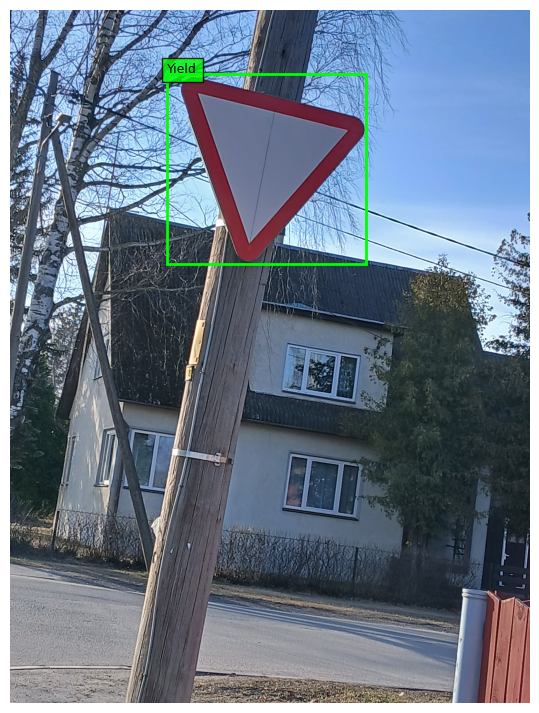

In [2]:
from pathlib import Path
from collections import defaultdict
from PIL import Image, ImageOps
import json
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import random

root = Path("/kaggle/input")
annotation_path = root / "competitions/traffic-sign-object-detection-challenge/train/annotations.json"

with open(annotation_path, encoding="utf-8") as f:
    coco = json.load(f)

# Index annotations by image ID
annotations_by_image = defaultdict(list)
for ann in coco["annotations"]:
    annotations_by_image[ann["image_id"]].append(ann)

# COCO category ID -> category name
categories = {
    cat["id"]: cat["name"]
    for cat in coco["categories"]
}

# Index images by relative path AND basename
image_paths = [
    p for p in root.rglob("*")
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
]

by_name = defaultdict(list)
for p in image_paths:
    by_name[p.name].append(p)

# Select an image that has annotations
image_info = random.choice([
    img for img in coco["images"]
    if annotations_by_image[img["id"]]
])

file_name = image_info["file_name"]
candidates = by_name[Path(file_name).name]

print("Image ID:", image_info["id"])
print("JSON filename:", file_name)
print("JSON dimensions:", image_info.get("width"),
      "x", image_info.get("height"))
print("Matching files:", candidates)

if len(candidates) != 1:
    raise ValueError(
        f"Expected exactly one matching file, found {len(candidates)}. "
        "Resolve the correct path using file_name and the dataset directory."
    )

image_path = candidates[0]

with Image.open(image_path) as im:
    print("Actual dimensions:", im.size)
    image = ImageOps.exif_transpose(im).convert("RGB")

fig, ax = plt.subplots(figsize=(14, 9))
ax.imshow(image)

for ann in annotations_by_image[image_info["id"]]:
    x, y, w, h = ann["bbox"]

    print(
        "Category:", categories.get(ann["category_id"], "Unknown"),
        "| bbox:", ann["bbox"]
    )

    rect = patches.Rectangle(
        (x, y), w, h,
        linewidth=2,
        edgecolor="lime",
        facecolor="none"
    )
    ax.add_patch(rect)

    ax.text(
        x, max(y - 5, 0),
        categories.get(ann["category_id"], str(ann["category_id"])),
        color="black",
        fontsize=9,
        bbox={"facecolor": "lime", "alpha": 0.8}
    )

ax.set_xlim(0, image.width)
ax.set_ylim(image.height, 0)
ax.axis("off")
plt.show()

,nombre_de_bounding_boxes
Crossroad,180
No entry,111
Speed limit,108
Yield,99
No stopping,96
No parking,94
Bus stop,89
direction of road,88


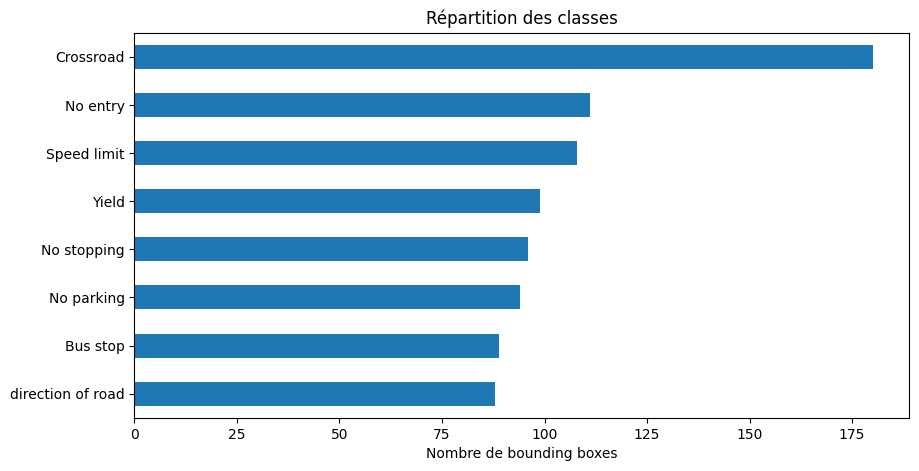

In [3]:
import pandas as pd

class_counts = pd.Series([
    categories[annotation["category_id"]]
    for annotation in coco["annotations"]
]).value_counts()

display(class_counts.to_frame("nombre_de_bounding_boxes"))

plt.figure(figsize=(10, 5))
class_counts.sort_values().plot(kind="barh")
plt.xlabel("Nombre de bounding boxes")
plt.title("Répartition des classes")
plt.show()

In [4]:
!pip install -q iterative-stratification

In [5]:
import numpy as np
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

image_ids = [image["id"] for image in coco["images"]]

# Une ligne par image, une colonne par classe
# Exemple : [0, 1, 0, 0, 1, 0, 0, 0]
# signifie que l'image contient Crossroad et No stopping.
label_matrix = np.zeros((len(image_ids), 8), dtype=int)

image_id_to_row = {
    image_id: row
    for row, image_id in enumerate(image_ids)
}

for annotation in coco["annotations"]:
    row = image_id_to_row[annotation["image_id"]]
    class_id = annotation["category_id"]

    label_matrix[row, class_id] = 1

splitter = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_rows, val_rows = next(
    splitter.split(
        X=np.zeros(len(image_ids)),
        y=label_matrix
    )
)

train_ids = {image_ids[index] for index in train_rows}
val_ids = {image_ids[index] for index in val_rows}

print("Train images :", len(train_ids))
print("Validation images :", len(val_ids))

Train images : 565
Validation images : 143


In [6]:
import shutil
import yaml
from collections import defaultdict
from pathlib import Path

# Change cette valeur si nécessaire :
source_root = root

output_root = Path("/kaggle/working/road_sign_yolo")

for split in ["train", "val"]:
    (output_root / "images" / split).mkdir(
        parents=True,
        exist_ok=True
    )

    (output_root / "labels" / split).mkdir(
        parents=True,
        exist_ok=True
    )

annotations_by_image = defaultdict(list)

for annotation in coco["annotations"]:
    annotations_by_image[annotation["image_id"]].append(annotation)

# Index de tous les fichiers image du dataset Kaggle
image_files = {
    path.name: path
    for path in source_root.rglob("*")
    if path.suffix.lower() in {".jpg", ".jpeg", ".png"}
}

def convert_image_to_yolo(image_info, split):
    image_id = image_info["id"]
    image_name = Path(image_info["file_name"]).name

    source_image = image_files[image_name]

    destination_image = (
        output_root / "images" / split / image_name
    )

    destination_label = (
        output_root / "labels" / split /
        f"{Path(image_name).stem}.txt"
    )

    shutil.copy2(source_image, destination_image)

    image_width = image_info["width"]
    image_height = image_info["height"]

    yolo_lines = []

    for annotation in annotations_by_image[image_id]:
        if annotation.get("ignore", 0) == 1:
            continue

        if annotation.get("iscrowd", 0) == 1:
            continue

        class_id = annotation["category_id"]

        x_min, y_min, width, height = annotation["bbox"]

        x_center = (x_min + width / 2) / image_width
        y_center = (y_min + height / 2) / image_height
        normalized_width = width / image_width
        normalized_height = height / image_height

        line = (
            f"{class_id} "
            f"{x_center:.6f} "
            f"{y_center:.6f} "
            f"{normalized_width:.6f} "
            f"{normalized_height:.6f}"
        )

        yolo_lines.append(line)

    destination_label.write_text(
        "\n".join(yolo_lines),
        encoding="utf-8"
    )

for image_info in coco["images"]:
    if image_info["id"] in train_ids:
        convert_image_to_yolo(image_info, "train")

    elif image_info["id"] in val_ids:
        convert_image_to_yolo(image_info, "val")

In [9]:
for split in ["train", "val"]:
    image_count = len(list((output_root / "images" / split).glob("*")))
    label_count = len(list((output_root / "labels" / split).glob("*.txt")))

    print(
        f"{split} | images : {image_count} | labels : {label_count}"
    )

train | images : 565 | labels : 565
val | images : 143 | labels : 143


path: /kaggle/working/road_sign_yolo
train: images/train
val: images/val
names:
- Bus stop
- Crossroad
- No entry
- No parking
- No stopping
- Speed limit
- Yield
- direction of road



In [35]:
class_names=[
        "Bus_stop",
        "Crossroad",  # Verify: Crossroad != Crosswalk
        "No_entry",
        "No_parking",
        "No_stopping",
        "Speed_limit",
        "Yield",
        "direction_of_road"
    ]

data_config = {
    "path": str(output_root),
    "train": "images/train",
    "val": "images/val",
    "names": class_names
}

yaml_path = output_root / "data.yaml"

with open(yaml_path, "w", encoding="utf-8") as file:
    yaml.safe_dump(
        data_config,
        file,
        sort_keys=False,
        allow_unicode=True
    )

print(yaml_path.read_text())

path: /kaggle/working/road_sign_yolo
train: images/train
val: images/val
names:
- Bus_stop
- Crossroad
- No_entry
- No_parking
- No_stopping
- Speed_limit
- Yield
- direction_of_road



In [16]:
import torch

!pip install -q -U ultralytics
print(torch.cuda.is_available())
device=('cuda'if torch.cuda.is_available() else 'cpu')
print(device)
from ultralytics import YOLO

data_yaml = "/kaggle/working/road_sign_yolo/data.yaml"

model = YOLO("yolo26s.pt")

results = model.train(
    data=data_yaml,
    epochs=50,
    imgsz=640,
    batch=16,
    device=device,

    optimizer="AdamW",
    lr0=0.001,

    patience=20,

    mosaic=0.5,
    mixup=0.0,

    project="/kaggle/working/yolo_runs",
    name="traffic_signs_yolo26s",
    exist_ok=True,

    seed=42,
    plots=True
)

True
cuda
Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/road_sign_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=traffic_signs_yolo26s, nbs=64, nms=Non

In [18]:
best_model = YOLO(
    "/kaggle/working/yolo_runs/traffic_signs_yolo26s/weights/best.pt"
)

metrics = best_model.val(
    data="/kaggle/working/road_sign_yolo/data.yaml",
    split="val",
    imgsz=640,
    batch=8,
    device=0,
    plots=True
)

print(f"Precision : {metrics.box.mp:.3f}")
print(f"Recall    : {metrics.box.mr:.3f}")
print(f"mAP@50    : {metrics.box.map50:.3f}")
print(f"mAP@50-95 : {metrics.box.map:.3f}")

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 120 layers, 9,468,276 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4995.8±504.9 MB/s, size: 4585.2 KB)
val: Scanning /kaggle/working/road_sign_yolo/labels/val.cache... 143 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 143/143 40.0Mit/s 0.0s
val: /kaggle/working/road_sign_yolo/images/val/0158e05f-20260314_175109.jpg: corrupt JPEG restored and saved
val: /kaggle/working/road_sign_yolo/images/val/0388be0d-20260314_173951.jpg: corrupt JPEG restored and saved
val: /kaggle/working/road_sign_yolo/images/val/054271ad-20260315_165157.jpg: corrupt JPEG restored and saved
val: /kaggle/working/road_sign_yolo/images/val/061eb56f-20260316_164202.jpg: corrupt JPEG restored and saved
val: /kaggle/working/road_sign_yolo/images/val/075d37d1-20260313_180937.jpg: corrupt JPEG restored and saved
val: /kaggle/working/road_sign_yolo/images/val/08638f83-2

In [19]:
prediction_results = best_model.predict(
    source="/kaggle/input/competitions/traffic-sign-object-detection-challenge/test/images",
    imgsz=640,
    conf=0.25,
    save=True,
    project="/kaggle/working/yolo_runs",
    name="val_predictions"
)


image 1/167 /kaggle/input/competitions/traffic-sign-object-detection-challenge/test/images/00ee5e76-IMG_1151.jpg: 640x480 2 Crossroads, 12.7ms
image 2/167 /kaggle/input/competitions/traffic-sign-object-detection-challenge/test/images/03eb5449-20260313_172307.jpg: 640x480 1 No stopping, 15.8ms
image 3/167 /kaggle/input/competitions/traffic-sign-object-detection-challenge/test/images/06386722-IMG_6428.JPG: 640x480 1 No stopping, 16.8ms
image 4/167 /kaggle/input/competitions/traffic-sign-object-detection-challenge/test/images/08ca7d8d-20260315_194633.jpg: 640x480 1 No parking, 1 Speed limit, 19.8ms
image 5/167 /kaggle/input/competitions/traffic-sign-object-detection-challenge/test/images/08e35074-20260315_192453.jpg: 640x480 1 Bus stop, 17.9ms
image 6/167 /kaggle/input/competitions/traffic-sign-object-detection-challenge/test/images/0b54fa85-20260315_193349.jpg: 640x480 1 Crossroad, 16.1ms
image 7/167 /kaggle/input/competitions/traffic-sign-object-detection-challenge/test/images/0ba9b720

In [24]:
from pathlib import Path
import pandas as pd

test_dir = Path(
    "/kaggle/input/competitions/traffic-sign-object-detection-challenge/test/images"
)

rows = []

for result in best_model.predict(
    source=str(test_dir),
    imgsz=640,
    conf=0.001,   # seuil bas pour produire les prédictions de soumission
    stream=True,
    verbose=False, device=device
):
    image_id = Path(result.path).stem
    prediction_parts = []

    if result.boxes is not None:
        for box in result.boxes:
            class_id = int(box.cls.item())
            confidence = float(box.conf.item())
            x1, y1, x2, y2 = box.xyxy[0].tolist()

            class_name = best_model.names[class_id]

            # À adapter exactement au format défini dans l’onglet Evaluation.
            prediction_parts.extend([
                str(class_name),
                f"{confidence:.6f}",
                f"{x1:.1f}",
                f"{y1:.1f}",
                f"{x2:.1f}",
                f"{y2:.1f}",
            ])

    rows.append({
        "image_id": image_id,
        "PredictionString": " ".join(prediction_parts)
    })

submission = pd.DataFrame(rows, columns=["image_id", "PredictionString"])
submission.to_csv("/kaggle/working/submission.csv", index=False)

print(submission.head())
print("CSV écrit :", "/kaggle/working/submission.csv")

                   image_id                                   PredictionString
0         00ee5e76-IMG_1151  Crossroad 0.749586 1305.0 2334.0 1555.7 2562.4...
1  03eb5449-20260313_172307  No stopping 0.755509 1604.8 1624.4 1798.9 1829...
2         06386722-IMG_6428  No stopping 0.878623 1453.3 1586.0 1932.3 2090...
3  08ca7d8d-20260315_194633  Speed limit 0.864159 514.4 954.8 1342.5 1798.4...
4  08e35074-20260315_192453      Bus stop 0.882802 1128.8 1072.9 2027.4 2317.9
CSV écrit : /kaggle/working/submission.csv


In [29]:
print(submission.iloc[0]["image_id"])
print(submission.iloc[0]["PredictionString"])

00ee5e76-IMG_1151
Crossroad 0.749586 1305.0 2334.0 1555.7 2562.4 Crossroad 0.452604 147.6 2610.2 279.0 2740.5


In [36]:
rows = []

for result in best_model.predict(
    source="/kaggle/input/competitions/traffic-sign-object-detection-challenge/test/images",
    imgsz=640,
    conf=0.25,
    stream=True,
    verbose=False
):
    image_id = Path(result.path).stem
    predictions = []

    if result.boxes is not None:
        for box in result.boxes:
            class_id = int(box.cls.item())
            x_min, y_min, x_max, y_max = box.xyxy[0].tolist()

            label = class_names[class_id]

            predictions.extend([
                label,
                 f"{float(box.conf.item()):.6f}",
                f"{x_min:.1f}",
                f"{y_min:.1f}",
                f"{x_max:.1f}",
                f"{y_max:.1f}",
            ])

    if predictions:
        prediction_string = " ".join(predictions)
    else:
        prediction_string = "No_parking 0.0001 0 0 1 1"

    rows.append({
        "image_id": image_id,
        "PredictionString": prediction_string
    })

submission = pd.DataFrame(
    rows,
    columns=["image_id", "PredictionString"]
)

submission.to_csv(
    "/kaggle/working/submission.csv",
    index=False
)

print(submission.head())
print("Nombre de lignes :", len(submission))
print("IDs uniques :", submission["image_id"].nunique())
print("CSV :", "/kaggle/working/submission.csv")

                   image_id                                   PredictionString
0         00ee5e76-IMG_1151  Crossroad 0.749586 1305.0 2334.0 1555.7 2562.4...
1  03eb5449-20260313_172307   No_stopping 0.755509 1604.8 1624.4 1798.9 1829.8
2         06386722-IMG_6428   No_stopping 0.878623 1453.3 1586.0 1932.3 2090.2
3  08ca7d8d-20260315_194633  Speed_limit 0.864159 514.4 954.8 1342.5 1798.4...
4  08e35074-20260315_192453      Bus_stop 0.882802 1128.8 1072.9 2027.4 2317.9
Nombre de lignes : 167
IDs uniques : 167
CSV : /kaggle/working/submission.csv


Image: /kaggle/input/competitions/traffic-sign-object-detection-challenge/test/images/0ba9b720-20260313_174517.jpg
Model classes: {0: 'Bus stop', 1: 'Crossroad', 2: 'No entry', 3: 'No parking', 4: 'No stopping', 5: 'Speed limit', 6: 'Yield', 7: 'direction of road'}
Original image dimensions: (4080, 3060)
Detections: 4
Class=Crossroad, confidence=0.805, xyxy=[0.9, 1361.1, 109.6, 1476.4]
Class=Crossroad, confidence=0.759, xyxy=[1810.6, 1358.6, 1942.5, 1483.9]
Class=Crossroad, confidence=0.660, xyxy=[1533.2, 1439.2, 1627.0, 1534.6]
Class=direction of road, confidence=0.428, xyxy=[1808.3, 1614.8, 1923.3, 1731.2]


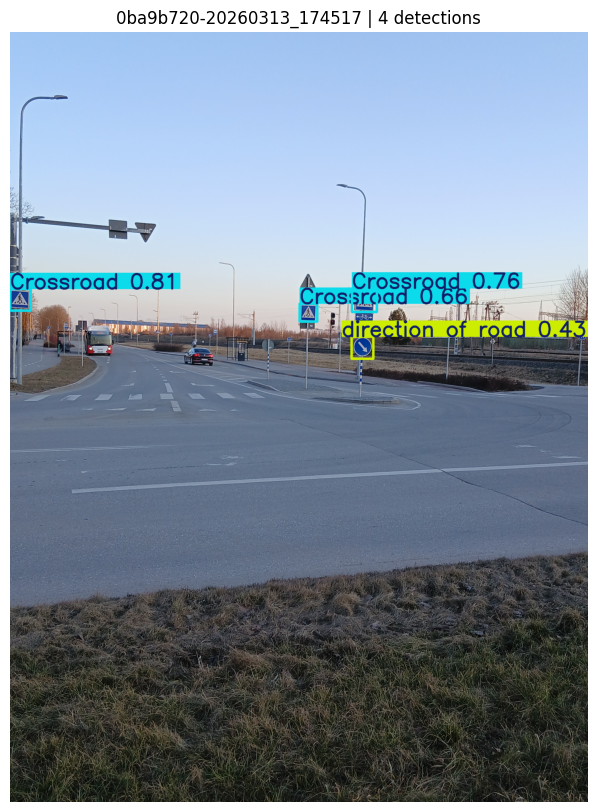

In [31]:
from pathlib import Path
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2

model = YOLO(
    "/kaggle/working/yolo_runs/traffic_signs_yolo26s/weights/best.pt"
)

test_dir = Path(
    "/kaggle/input/competitions/traffic-sign-object-detection-challenge/test"
)

image_id = "0ba9b720-20260313_174517"

matches = [
    p for p in test_dir.rglob("*")
    if p.is_file()
    and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    and p.stem == image_id
]

if not matches:
    raise FileNotFoundError(f"Image ID not found: {image_id}")

image_path = matches[0]

print("Image:", image_path)
print("Model classes:", model.names)

# Predict using a reasonable visualization threshold
result = model.predict(
    source=str(image_path),
    imgsz=640,
    conf=0.25,
    iou=0.7,
    device=0,
    verbose=False
)[0]

print("Original image dimensions:", result.orig_shape)
print("Detections:", len(result.boxes))

for box in result.boxes:
    cls_id = int(box.cls.item())
    conf = float(box.conf.item())
    xyxy = box.xyxy[0].tolist()

    print(
        f"Class={model.names[cls_id]}, "
        f"confidence={conf:.3f}, "
        f"xyxy={[round(v, 1) for v in xyxy]}"
    )

# YOLO plot() returns a BGR image; convert it to RGB for Matplotlib
annotated = result.plot()

plt.figure(figsize=(14, 10))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.title(f"{image_id} | {len(result.boxes)} detections")
plt.axis("off")
plt.show()